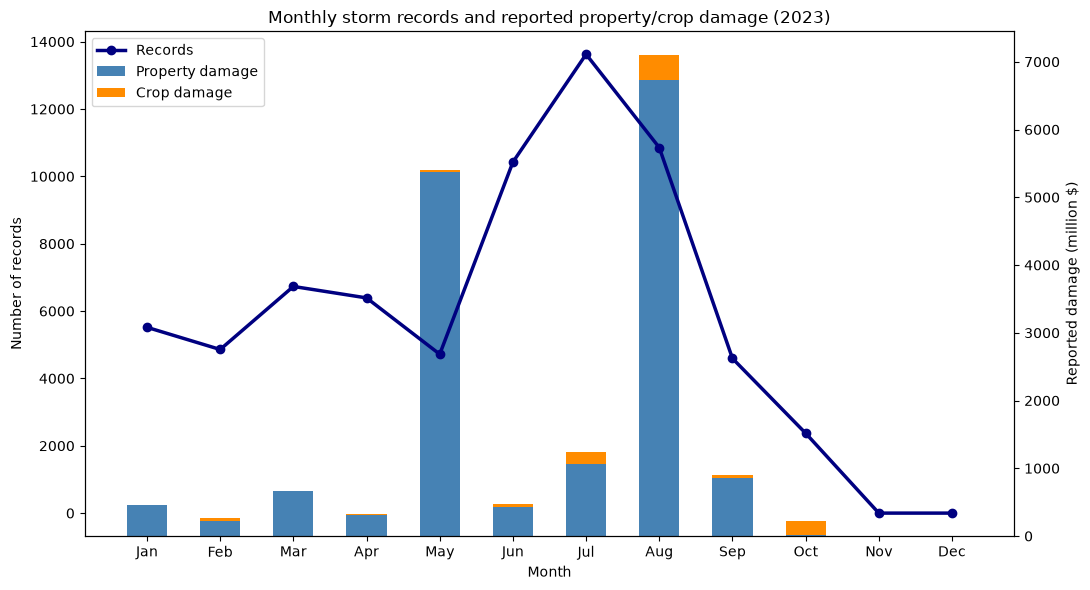

In [2]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def format_damage_table(frame):
    damage_columns = (
        column
        for column in ("property_damage", "crop_damage", "total_damage")
        if column in frame.columns
    )
    formatters = {column: lambda value: f"${value:,.2f}" for column in damage_columns}
    return (
        frame.style.format(formatters, na_rep="—")
        .set_table_attributes('style="width:100%; table-layout:auto;"')
        .set_properties(**{"white-space": "nowrap"})
    )

# Find data/data.db from the current notebook working directory or its parents.
database_path = None
for directory in (Path.cwd(), *Path.cwd().parents):
    candidate = directory / "data" / "data.db"
    if candidate.is_file():
        database_path = candidate
        break

if database_path is None:
    raise FileNotFoundError(f"Could not locate data/data.db from {Path.cwd()}")

query = """
SELECT
    BEGIN_DATE_TIME AS date,
    STATE AS state,
    EVENT_TYPE AS event_type,
    COALESCE(DAMAGE_PROPERTY, 0) AS property_damage,
    COALESCE(DAMAGE_CROPS, 0) AS crop_damage
FROM StormEvents
"""
with sqlite3.connect(database_path) as connection:
    data = pd.read_sql_query(query, connection)

data["date"] = pd.to_datetime(data["date"], errors="coerce")
data = data.dropna(subset=["date"]).copy()

monthly = (
    data.assign(month=data["date"].dt.month)
    .groupby("month")
    .agg(
        records=("date", "size"),
        property_damage=("property_damage", "sum"),
        crop_damage=("crop_damage", "sum"),
    )
    .reindex(range(1, 13), fill_value=0)
)

fig, ax1 = plt.subplots(figsize=(11, 6))
ax2 = ax1.twinx()
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)
months = monthly.index.to_numpy()
width = 0.55
ax2.bar(
    months,
    monthly["property_damage"] / 1_000_000,
    width=width,
    label="Property damage",
    color="steelblue",
)
ax2.bar(
    months,
    monthly["crop_damage"] / 1_000_000,
    width=width,
    bottom=monthly["property_damage"] / 1_000_000,
    label="Crop damage",
    color="darkorange",
)
ax1.plot(
    months,
    monthly["records"],
    marker="o",
    color="navy",
    label="Records",
    linewidth=2.5,
    zorder=10,
)
ax1.set_xticks(months)
ax1.set_xticklabels(
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
ax1.set_xlabel("Month")
ax1.set_ylabel("Number of records")
ax2.set_ylabel("Reported damage (million $)")
ax1.set_title("Monthly storm records and reported property/crop damage (2023)")
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")
plt.tight_layout()
plt.show()


In [8]:
# Investigate what drove the August property and crop damage totals.
august = pd.read_sql_query(
    """
    SELECT
        BEGIN_DATE_TIME AS date,
        STATE AS state,
        EVENT_TYPE AS event_type,
        COALESCE(DAMAGE_PROPERTY, 0) AS property_damage,
        COALESCE(DAMAGE_CROPS, 0) AS crop_damage
    FROM StormEvents
    WHERE date(BEGIN_DATE_TIME) >= '2023-08-01'
      AND date(BEGIN_DATE_TIME) <  '2023-09-01'
    """,
    connection,
)
august["date"] = pd.to_datetime(august["date"], errors="coerce")
august = august.dropna(subset=["date"]).copy()
august["total_damage"] = august["property_damage"] + august["crop_damage"]

by_event = (
    august.groupby("event_type", as_index=False)
    .agg(
        events=("date", "size"),
        property_damage=("property_damage", "sum"),
        crop_damage=("crop_damage", "sum"),
    )
    .assign(total_damage=lambda d: d["property_damage"] + d["crop_damage"])
    .sort_values("total_damage", ascending=False)
)
print("Top event types by reported damage in August 2023:")
def format_damage_table(frame):
    damage_columns = (
        column
        for column in ("property_damage", "crop_damage", "total_damage")
        if column in frame.columns
    )
    formatters = {column: lambda value: f"${value:,.2f}" for column in damage_columns}
    return (
        frame.style.format(formatters, na_rep="—")
        .set_table_attributes('style="width:100%; table-layout:auto;"')
        .set_properties(**{"white-space": "nowrap"})
    )

display(format_damage_table(by_event.head(15)))

by_state = (
    august.groupby("state", as_index=False)
    .agg(
        events=("date", "size"),
        property_damage=("property_damage", "sum"),
        crop_damage=("crop_damage", "sum"),
    )
    .assign(total_damage=lambda d: d["property_damage"] + d["crop_damage"])
    .sort_values("total_damage", ascending=False)
)
print()
print("Top states by reported damage in August 2023:")
display(format_damage_table(by_state.head(15)))

top_event = by_event.iloc[0]["event_type"]
top_event_records = (
    august[august["event_type"] == top_event]
    .sort_values("total_damage", ascending=False)
    .head(10)
)
print()
print(f"Largest August damage records for {top_event}:")
display(
    format_damage_table(
        top_event_records[
            ["date", "state", "event_type", "property_damage", "crop_damage", "total_damage"]
        ]
    )
)

monthly_event = (
    pd.read_sql_query(
        """
        SELECT
            CAST(strftime('%m', BEGIN_DATE_TIME) AS INTEGER) AS month,
            EVENT_TYPE AS event_type,
            COALESCE(DAMAGE_PROPERTY, 0) AS property_damage,
            COALESCE(DAMAGE_CROPS, 0) AS crop_damage
        FROM StormEvents
        WHERE date(BEGIN_DATE_TIME) >= '2023-01-01'
          AND date(BEGIN_DATE_TIME) <  '2024-01-01'
        """,
        connection,
    )
    .groupby(["month", "event_type"], as_index=False)
    .agg(
        property_damage=("property_damage", "sum"),
        crop_damage=("crop_damage", "sum"),
    )
)
top_event_monthly = (
    monthly_event[monthly_event["event_type"] == top_event]
    .sort_values("month")
    .reset_index(drop=True)
)
print()
print(f"Monthly damage pattern for {top_event}:")
display(format_damage_table(top_event_monthly))


Top event types by reported damage in August 2023:


,event_type,events,property_damage,crop_damage,total_damage
32,Wildfire,83,"$5,726,020,750.00",$0.00,"$5,726,020,750.00"
8,Flash Flood,581,"$610,463,100.00","$210,000.00","$610,673,100.00"
15,Hurricane,11,"$63,500,000.00","$270,000,000.00","$333,500,000.00"
27,Thunderstorm Wind,3686,"$148,701,010.00","$9,842,900.00","$158,543,910.00"
28,Tornado,138,"$97,245,000.00","$54,000.00","$97,299,000.00"
30,Tropical Storm,171,"$21,765,000.00","$67,500,000.00","$89,265,000.00"
11,Hail,904,"$23,793,400.00","$6,967,000.00","$30,760,400.00"
25,Storm Surge/Tide,22,"$25,000,000.00",$0.00,"$25,000,000.00"
9,Flood,163,"$11,744,200.00","$60,500.00","$11,804,700.00"
5,Drought,551,$0.00,"$6,663,000.00","$6,663,000.00"



Top states by reported damage in August 2023:


,state,events,property_damage,crop_damage,total_damage
15,HAWAII,22,"$5,554,600,000.00",$0.00,"$5,554,600,000.00"
6,CALIFORNIA,218,"$514,617,000.00",$0.00,"$514,617,000.00"
11,FLORIDA,380,"$72,701,700.00","$337,500,000.00","$410,201,700.00"
32,MICHIGAN,86,"$182,698,000.00",$0.00,"$182,698,000.00"
58,WASHINGTON,9,"$89,755,750.00",$0.00,"$89,755,750.00"
12,GEORGIA,794,"$39,320,000.00",$500.00,"$39,320,500.00"
30,MARYLAND,104,"$39,096,000.00",$0.00,"$39,096,000.00"
16,IDAHO,87,"$38,399,200.00","$9,500.00","$38,408,700.00"
28,LOUISIANA,840,"$22,949,750.00","$4,000,000.00","$26,949,750.00"
38,NEVADA,33,"$25,630,100.00",$0.00,"$25,630,100.00"



Largest August damage records for Wildfire:


,date,state,event_type,property_damage,crop_damage,total_damage
10806,2023-08-08 06:40:00,HAWAII,Wildfire,"$5,500,000,000.00",$0.00,"$5,500,000,000.00"
9928,2023-08-18 12:27:00,WASHINGTON,Wildfire,"$60,000,000.00",$0.00,"$60,000,000.00"
10169,2023-08-08 00:00:00,HAWAII,Wildfire,"$54,600,000.00",$0.00,"$54,600,000.00"
401,2023-08-03 14:25:00,IDAHO,Wildfire,"$24,000,000.00",$0.00,"$24,000,000.00"
5759,2023-08-22 12:30:00,LOUISIANA,Wildfire,"$16,880,000.00",$0.00,"$16,880,000.00"
10178,2023-08-18 16:00:00,WASHINGTON,Wildfire,"$15,000,000.00",$0.00,"$15,000,000.00"
10730,2023-08-01 00:00:00,WASHINGTON,Wildfire,"$9,900,000.00",$0.00,"$9,900,000.00"
10794,2023-08-01 00:00:00,IDAHO,Wildfire,"$9,200,000.00",$0.00,"$9,200,000.00"
5450,2023-08-24 12:00:00,TEXAS,Wildfire,"$7,000,000.00",$0.00,"$7,000,000.00"
10249,2023-08-05 21:13:00,IDAHO,Wildfire,"$5,000,000.00",$0.00,"$5,000,000.00"



Monthly damage pattern for Wildfire:


,month,event_type,property_damage,crop_damage
0,1,Wildfire,$0.00,$0.00
1,2,Wildfire,"$500,000.00",$0.00
2,3,Wildfire,"$2,016,190.00","$120,000.00"
3,4,Wildfire,"$4,743,180.00","$950,000.00"
4,5,Wildfire,"$250,000.00",$0.00
5,6,Wildfire,"$17,980,000.00",$0.00
6,7,Wildfire,"$39,348,500.00",$0.00
7,8,Wildfire,"$5,726,020,750.00",$0.00
8,9,Wildfire,"$110,779,900.00",$0.00
9,10,Wildfire,"$3,975,000.00",$0.00


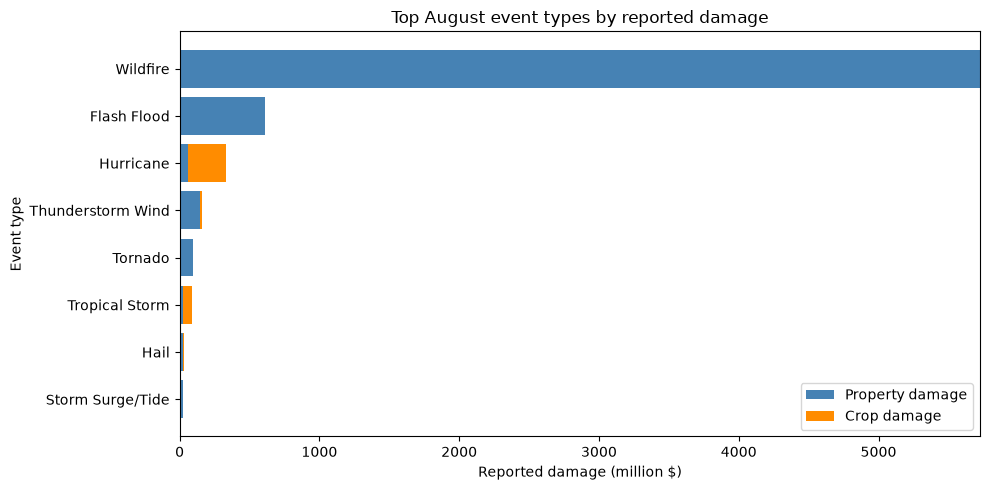

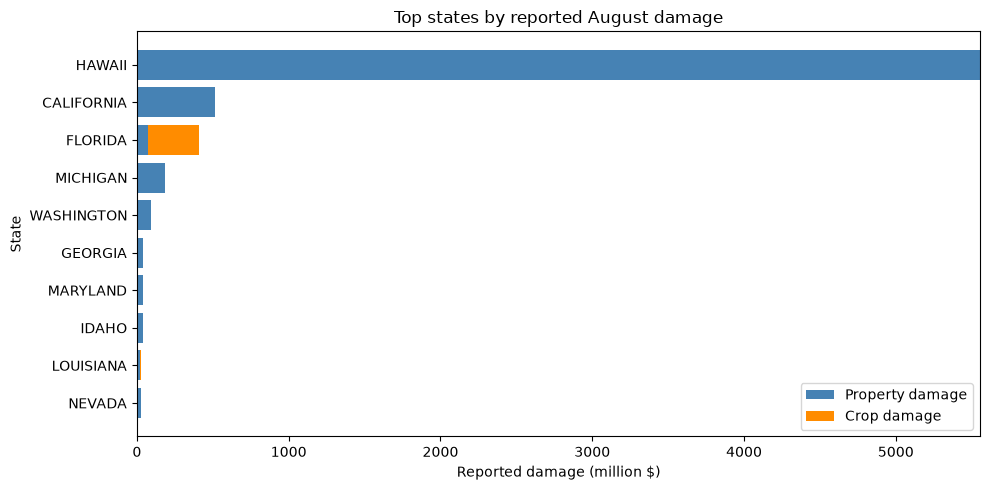

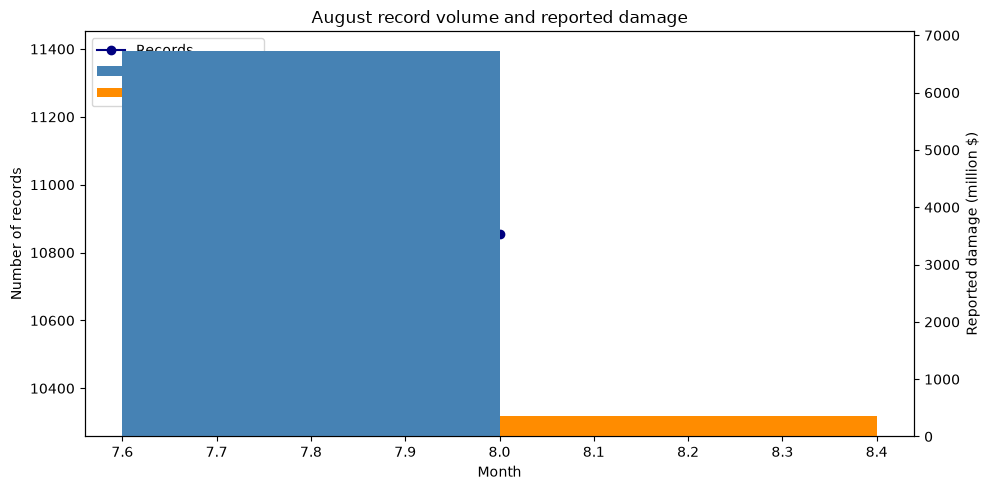

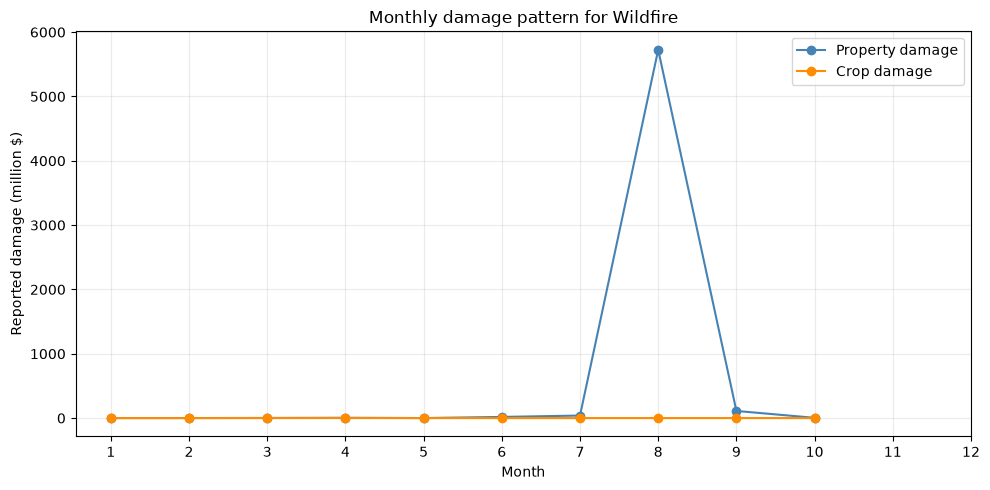

In [9]:
# August damage visualizations
event_chart = by_event.head(8).sort_values("total_damage", ascending=True)
fig1, ax1 = plt.subplots(figsize=(10, 5))
y = np.arange(len(event_chart))
ax1.barh(
    y,
    event_chart["property_damage"] / 1_000_000,
    color="steelblue",
    label="Property damage",
)
ax1.barh(
    y,
    event_chart["crop_damage"] / 1_000_000,
    left=event_chart["property_damage"] / 1_000_000,
    color="darkorange",
    label="Crop damage",
)
ax1.set_yticks(y)
ax1.set_yticklabels(event_chart["event_type"])
ax1.set_xlabel("Reported damage (million $)")
ax1.set_ylabel("Event type")
ax1.set_title("Top August event types by reported damage")
ax1.legend(loc="lower right")
plt.tight_layout()
plt.show()

state_chart = by_state.head(10).sort_values("total_damage", ascending=True)
fig2, ax2 = plt.subplots(figsize=(10, 5))
y = np.arange(len(state_chart))
ax2.barh(
    y,
    state_chart["property_damage"] / 1_000_000,
    color="steelblue",
    label="Property damage",
)
ax2.barh(
    y,
    state_chart["crop_damage"] / 1_000_000,
    left=state_chart["property_damage"] / 1_000_000,
    color="darkorange",
    label="Crop damage",
)
ax2.set_yticks(y)
ax2.set_yticklabels(state_chart["state"])
ax2.set_xlabel("Reported damage (million $)")
ax2.set_ylabel("State")
ax2.set_title("Top states by reported August damage")
ax2.legend(loc="lower right")
plt.tight_layout()
plt.show()

august_monthly = (
    august.assign(month=august["date"].dt.month)
    .groupby("month")
    .agg(
        records=("date", "size"),
        property_damage=("property_damage", "sum"),
        crop_damage=("crop_damage", "sum"),
    )
)
fig3, ax3 = plt.subplots(figsize=(10, 5))
ax3.plot(
    august_monthly.index,
    august_monthly["records"],
    marker="o",
    color="navy",
    label="Records",
)
ax3.set_xlabel("Month")
ax3.set_ylabel("Number of records")
ax3.set_title("August record volume and reported damage")
ax4 = ax3.twinx()
ax4.bar(
    august_monthly.index - 0.2,
    august_monthly["property_damage"] / 1_000_000,
    width=0.4,
    color="steelblue",
    label="Property damage",
)
ax4.bar(
    august_monthly.index + 0.2,
    august_monthly["crop_damage"] / 1_000_000,
    width=0.4,
    color="darkorange",
    label="Crop damage",
)
ax4.set_ylabel("Reported damage (million $)")
handles1, labels1 = ax3.get_legend_handles_labels()
handles2, labels2 = ax4.get_legend_handles_labels()
ax3.legend(handles1 + handles2, labels1 + labels2, loc="upper left")
plt.tight_layout()
plt.show()

fig4, ax5 = plt.subplots(figsize=(10, 5))
ax5.plot(
    top_event_monthly["month"],
    top_event_monthly["property_damage"] / 1_000_000,
    marker="o",
    color="steelblue",
    label="Property damage",
)
ax5.plot(
    top_event_monthly["month"],
    top_event_monthly["crop_damage"] / 1_000_000,
    marker="o",
    color="darkorange",
    label="Crop damage",
)
ax5.set_xlabel("Month")
ax5.set_ylabel("Reported damage (million $)")
ax5.set_xticks(range(1, 13))
ax5.set_title(f"Monthly damage pattern for {top_event}")
ax5.grid(alpha=0.25)
ax5.legend()
plt.tight_layout()
plt.show()


Top event types by reported damage in Jun-Aug 2023:


,event_type,events,property_damage,crop_damage,total_damage
39,Wildfire,162,"$5,783,349,250.00",$0.00,"$5,783,349,250.00"
12,Flash Flood,1901,"$1,169,109,550.00","$2,538,100.00","$1,171,647,650.00"
33,Thunderstorm Wind,14377,"$511,857,780.00","$42,317,810.00","$554,175,590.00"
34,Tornado,506,"$413,501,000.00","$1,568,800.00","$415,069,800.00"
21,Hurricane,11,"$63,500,000.00","$270,000,000.00","$333,500,000.00"
16,Hail,5807,"$187,438,150.00","$93,037,400.00","$280,475,550.00"
7,Drought,1295,"$850,000.00","$107,353,000.00","$108,203,000.00"
36,Tropical Storm,172,"$21,765,000.00","$67,500,000.00","$89,265,000.00"
31,Storm Surge/Tide,22,"$25,000,000.00",$0.00,"$25,000,000.00"
22,Lightning,178,"$21,203,500.00","$951,000.00","$22,154,500.00"



Top states by reported damage in Jun-Aug 2023:


,state,events,property_damage,crop_damage,total_damage
16,HAWAII,41,"$5,554,600,000.00",$0.00,"$5,554,600,000.00"
7,CALIFORNIA,472,"$517,624,000.00",$20.00,"$517,624,020.00"
18,ILLINOIS,1214,"$512,540,000.00",$0.00,"$512,540,000.00"
12,FLORIDA,925,"$73,864,500.00","$337,503,000.00","$411,367,500.00"
44,NORTH CAROLINA,845,"$304,970,400.00","$908,500.00","$305,878,900.00"
33,MICHIGAN,392,"$208,133,000.00","$1,010,000.00","$209,143,000.00"
47,OKLAHOMA,2225,"$169,421,000.00",$0.00,"$169,421,000.00"
55,TEXAS,3506,"$155,688,500.00","$1,000.00","$155,689,500.00"
38,NEBRASKA,1029,"$29,768,250.00","$113,027,500.00","$142,795,750.00"
60,WASHINGTON,47,"$109,589,750.00","$40,000.00","$109,629,750.00"



Largest Jun-Aug damage records for Wildfire:


,date,state,event_type,property_damage,crop_damage,total_damage
34778,2023-08-08 06:40:00,HAWAII,Wildfire,"$5,500,000,000.00",$0.00,"$5,500,000,000.00"
32737,2023-08-18 12:27:00,WASHINGTON,Wildfire,"$60,000,000.00",$0.00,"$60,000,000.00"
33296,2023-08-08 00:00:00,HAWAII,Wildfire,"$54,600,000.00",$0.00,"$54,600,000.00"
2294,2023-08-03 14:25:00,IDAHO,Wildfire,"$24,000,000.00",$0.00,"$24,000,000.00"
24976,2023-08-22 12:30:00,LOUISIANA,Wildfire,"$16,880,000.00",$0.00,"$16,880,000.00"
33309,2023-08-18 16:00:00,WASHINGTON,Wildfire,"$15,000,000.00",$0.00,"$15,000,000.00"
34601,2023-08-01 00:00:00,WASHINGTON,Wildfire,"$9,900,000.00",$0.00,"$9,900,000.00"
11109,2023-07-01 00:00:00,IDAHO,Wildfire,"$9,200,000.00",$0.00,"$9,200,000.00"
34761,2023-08-01 00:00:00,IDAHO,Wildfire,"$9,200,000.00",$0.00,"$9,200,000.00"
998,2023-06-30 08:00:00,IDAHO,Wildfire,"$9,200,000.00",$0.00,"$9,200,000.00"



Monthly damage pattern for Wildfire (Jun-Aug):


,month,event_type,property_damage,crop_damage
0,6,Wildfire,"$17,980,000.00",$0.00
1,7,Wildfire,"$39,348,500.00",$0.00
2,8,Wildfire,"$5,726,020,750.00",$0.00


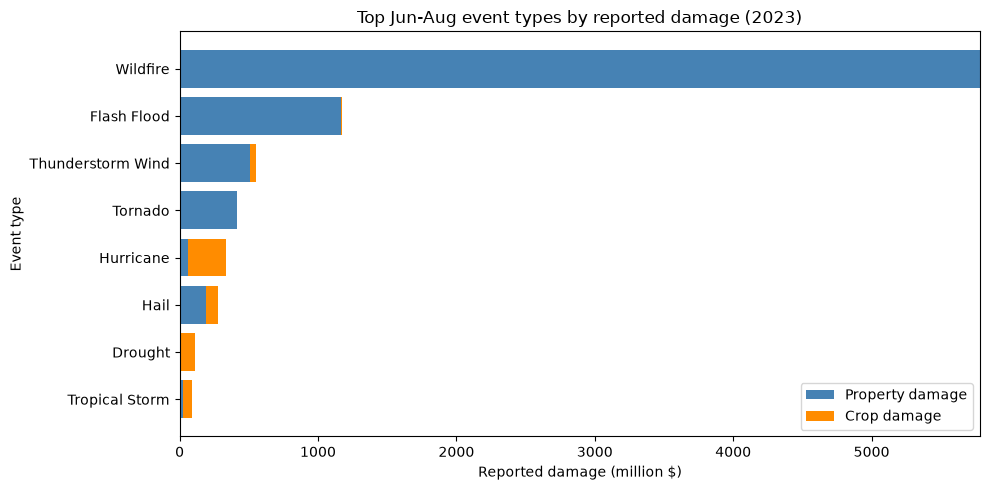

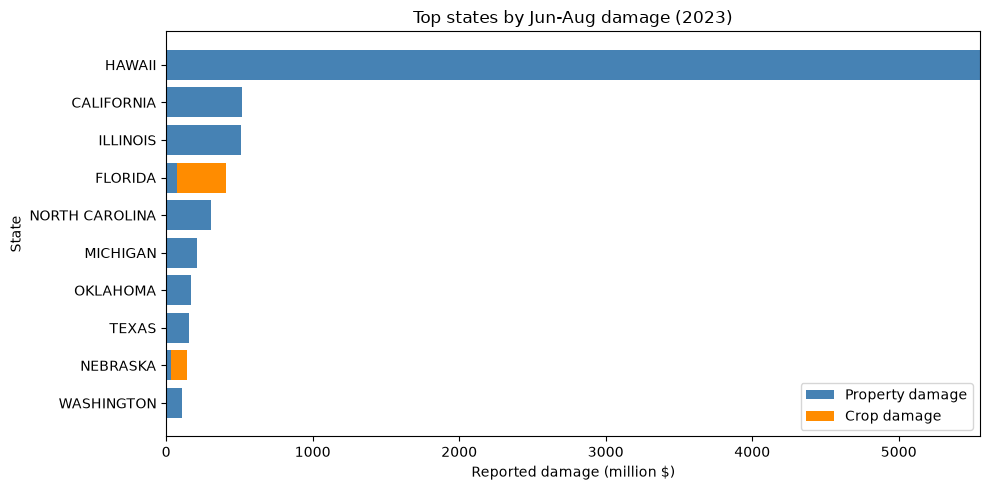

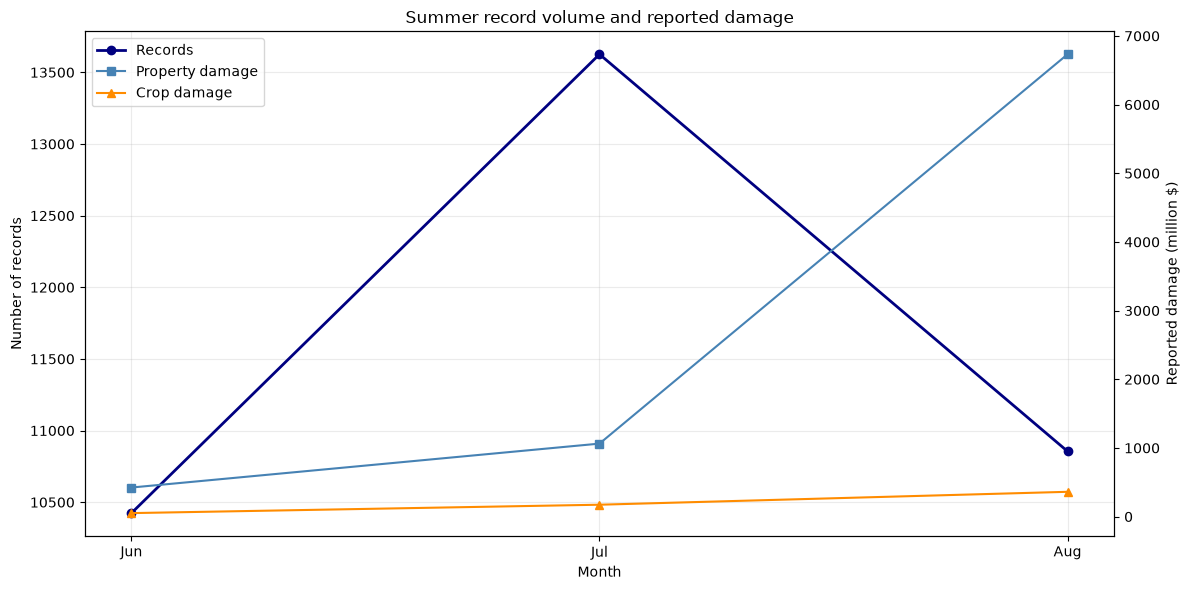

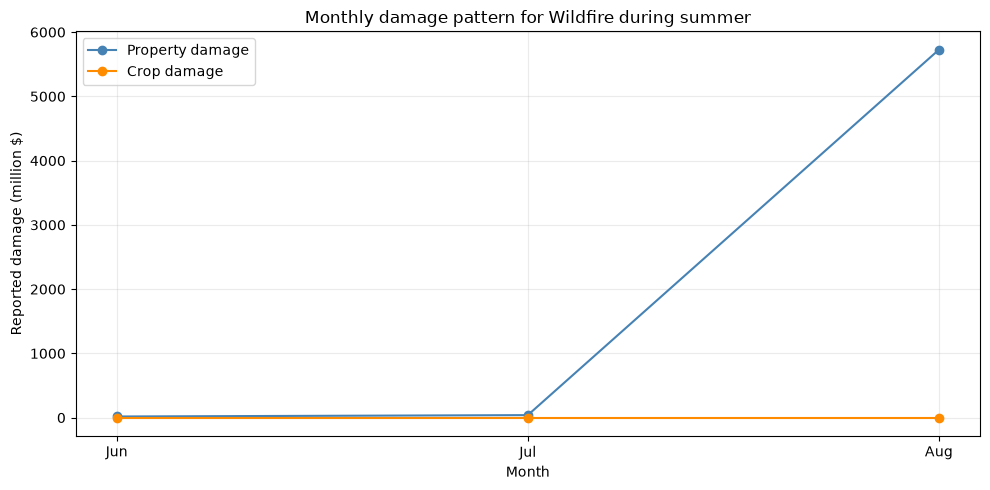

In [10]:
# June-July-August 2023 damage analysis
summer = pd.read_sql_query(
    """
    SELECT
        BEGIN_DATE_TIME AS date,
        STATE AS state,
        EVENT_TYPE AS event_type,
        COALESCE(DAMAGE_PROPERTY, 0) AS property_damage,
        COALESCE(DAMAGE_CROPS, 0) AS crop_damage
    FROM StormEvents
    WHERE date(BEGIN_DATE_TIME) >= '2023-06-01'
      AND date(BEGIN_DATE_TIME) <  '2023-09-01'
    """,
    connection,
)
summer["date"] = pd.to_datetime(summer["date"], errors="coerce")
summer = summer.dropna(subset=["date"]).copy()
summer["total_damage"] = summer["property_damage"] + summer["crop_damage"]

by_event = (
    summer.groupby("event_type", as_index=False)
    .agg(
        events=("date", "size"),
        property_damage=("property_damage", "sum"),
        crop_damage=("crop_damage", "sum"),
    )
    .assign(total_damage=lambda d: d["property_damage"] + d["crop_damage"])
    .sort_values("total_damage", ascending=False)
)
print("Top event types by reported damage in Jun-Aug 2023:")
display(format_damage_table(by_event.head(15)))

by_state = (
    summer.groupby("state", as_index=False)
    .agg(
        events=("date", "size"),
        property_damage=("property_damage", "sum"),
        crop_damage=("crop_damage", "sum"),
    )
    .assign(total_damage=lambda d: d["property_damage"] + d["crop_damage"])
    .sort_values("total_damage", ascending=False)
)
print()
print("Top states by reported damage in Jun-Aug 2023:")
display(format_damage_table(by_state.head(15)))

top_event = by_event.iloc[0]["event_type"]
top_event_records = (
    summer[summer["event_type"] == top_event]
    .sort_values("total_damage", ascending=False)
    .head(10)
)
print()
print(f"Largest Jun-Aug damage records for {top_event}:")
display(
    format_damage_table(
        top_event_records[
            ["date", "state", "event_type", "property_damage", "crop_damage", "total_damage"]
        ]
    )
)

monthly_event = (
    summer.assign(month=summer["date"].dt.month)
    .groupby(["month", "event_type"], as_index=False)
    .agg(
        property_damage=("property_damage", "sum"),
        crop_damage=("crop_damage", "sum"),
    )
)
top_event_monthly = (
    monthly_event[monthly_event["event_type"] == top_event]
    .sort_values("month")
    .reset_index(drop=True)
)
print()
print(f"Monthly damage pattern for {top_event} (Jun-Aug):")
display(format_damage_table(top_event_monthly))

summer_monthly = (
    summer.assign(month=summer["date"].dt.month)
    .groupby("month")
    .agg(
        records=("date", "size"),
        property_damage=("property_damage", "sum"),
        crop_damage=("crop_damage", "sum"),
    )
    .reindex([6, 7, 8], fill_value=0)
)

event_chart = by_event.head(8).sort_values("total_damage", ascending=True)
fig1, ax1 = plt.subplots(figsize=(10, 5))
y = np.arange(len(event_chart))
ax1.barh(
    y,
    event_chart["property_damage"] / 1_000_000,
    color="steelblue",
    label="Property damage",
)
ax1.barh(
    y,
    event_chart["crop_damage"] / 1_000_000,
    left=event_chart["property_damage"] / 1_000_000,
    color="darkorange",
    label="Crop damage",
)
ax1.set_yticks(y)
ax1.set_yticklabels(event_chart["event_type"])
ax1.set_xlabel("Reported damage (million $)")
ax1.set_ylabel("Event type")
ax1.set_title("Top Jun-Aug event types by reported damage (2023)")
ax1.legend(loc="lower right")
plt.tight_layout()
plt.show()

state_chart = by_state.head(10).sort_values("total_damage", ascending=True)
fig2, ax2 = plt.subplots(figsize=(10, 5))
y = np.arange(len(state_chart))
ax2.barh(
    y,
    state_chart["property_damage"] / 1_000_000,
    color="steelblue",
    label="Property damage",
)
ax2.barh(
    y,
    state_chart["crop_damage"] / 1_000_000,
    left=state_chart["property_damage"] / 1_000_000,
    color="darkorange",
    label="Crop damage",
)
ax2.set_yticks(y)
ax2.set_yticklabels(state_chart["state"])
ax2.set_xlabel("Reported damage (million $)")
ax2.set_ylabel("State")
ax2.set_title("Top states by Jun-Aug damage (2023)")
ax2.legend(loc="lower right")
plt.tight_layout()
plt.show()

fig3, ax3 = plt.subplots(figsize=(12, 6))
ax3.plot(
    summer_monthly.index,
    summer_monthly["records"],
    marker="o",
    color="navy",
    linewidth=2,
    label="Records",
)
ax3.set_xlabel("Month")
ax3.set_ylabel("Number of records")
ax3.set_xticks([6, 7, 8])
ax3.set_xticklabels(["Jun", "Jul", "Aug"])
ax3.set_title("Summer record volume and reported damage")
ax3.grid(alpha=0.25)
ax4 = ax3.twinx()
ax4.plot(
    summer_monthly.index,
    summer_monthly["property_damage"] / 1_000_000,
    marker="s",
    color="steelblue",
    label="Property damage",
)
ax4.plot(
    summer_monthly.index,
    summer_monthly["crop_damage"] / 1_000_000,
    marker="^",
    color="darkorange",
    label="Crop damage",
)
ax4.set_ylabel("Reported damage (million $)")
handles1, labels1 = ax3.get_legend_handles_labels()
handles2, labels2 = ax4.get_legend_handles_labels()
ax3.legend(handles1 + handles2, labels1 + labels2, loc="upper left")
plt.tight_layout()
plt.show()

fig4, ax5 = plt.subplots(figsize=(10, 5))
ax5.plot(
    top_event_monthly["month"],
    top_event_monthly["property_damage"] / 1_000_000,
    marker="o",
    color="steelblue",
    label="Property damage",
)
ax5.plot(
    top_event_monthly["month"],
    top_event_monthly["crop_damage"] / 1_000_000,
    marker="o",
    color="darkorange",
    label="Crop damage",
)
ax5.set_xlabel("Month")
ax5.set_ylabel("Reported damage (million $)")
ax5.set_xticks([6, 7, 8])
ax5.set_xticklabels(["Jun", "Jul", "Aug"])
ax5.set_title(f"Monthly damage pattern for {top_event} during summer")
ax5.grid(alpha=0.25)
ax5.legend()
plt.tight_layout()
plt.show()


In [12]:
# Analyze May damage patterns.
may = pd.read_sql_query(
    """
    SELECT
        CAST(strftime('%m', BEGIN_DATE_TIME) AS INTEGER) AS month,
        STATE AS state,
        EVENT_TYPE AS event_type,
        COALESCE(DAMAGE_PROPERTY, 0) AS property_damage,
        COALESCE(DAMAGE_CROPS, 0) AS crop_damage
    FROM StormEvents
    WHERE CAST(strftime('%m', BEGIN_DATE_TIME) AS INTEGER) = 5
    """,
    connection,
)
may["month_name"] = "May"
may["total_damage"] = may["property_damage"] + may["crop_damage"]

top_events = (
    may.groupby(["month_name", "event_type"], as_index=False)
    .agg(
        events=("event_type", "size"),
        property_damage=("property_damage", "sum"),
        crop_damage=("crop_damage", "sum"),
    )
    .assign(total_damage=lambda d: d["property_damage"] + d["crop_damage"])
    .sort_values(["month_name", "total_damage"], ascending=[True, False])
)
print("Top event types by damage in May:")
display(format_damage_table(top_events.head(30)))

top_states = (
    may.groupby(["month_name", "state"], as_index=False)
    .agg(
        events=("event_type", "size"),
        property_damage=("property_damage", "sum"),
        crop_damage=("crop_damage", "sum"),
    )
    .assign(total_damage=lambda d: d["property_damage"] + d["crop_damage"])
    .sort_values(["month_name", "total_damage"], ascending=[True, False])
)
print()
print("Top states by damage in May:")
display(format_damage_table(top_states.head(30)))

for month_name in ["May"]:
    print()
    print(f"=== {month_name} top event types by total damage ===")
    display(
        format_damage_table(
            top_events[top_events["month_name"] == month_name]
            .sort_values(["total_damage", "events"], ascending=[False, False])
            .head(10)
        )
    )


Top event types by damage in May:


,month_name,event_type,events,property_damage,crop_damage,total_damage
17,May,Hurricane,3,"$4,000,000,000.00","$10,000,000.00","$4,010,000,000.00"
11,May,Hail,1768,"$1,327,117,000.00","$2,981,300.00","$1,330,098,300.00"
24,May,Thunderstorm Wind,1235,"$15,180,100.00","$128,000.00","$15,308,100.00"
8,May,Flood,270,"$11,489,410.00","$2,836,130.00","$14,325,540.00"
9,May,Frost/Freeze,131,$0.00,"$7,275,000.00","$7,275,000.00"
7,May,Flash Flood,341,"$6,528,100.00","$590,040.00","$7,118,140.00"
5,May,Drought,283,$0.00,"$6,408,000.00","$6,408,000.00"
25,May,Tornado,180,"$4,256,500.00","$19,800.00","$4,276,300.00"
3,May,Debris Flow,17,"$2,567,000.00",$0.00,"$2,567,000.00"
29,May,Winter Storm,18,"$2,100,000.00",$0.00,"$2,100,000.00"



Top states by damage in May:


,month_name,state,events,property_damage,crop_damage,total_damage
12,May,GUAM,4,"$4,000,000,000.00","$10,000,000.00","$4,010,000,000.00"
46,May,TEXAS,735,"$1,305,486,300.00",$0.00,"$1,305,486,300.00"
31,May,NEBRASKA,319,"$19,165,500.00","$2,672,010.00","$21,837,510.00"
35,May,NEW MEXICO,198,"$9,705,000.00","$10,000.00","$9,715,000.00"
48,May,VERMONT,22,$0.00,"$7,275,000.00","$7,275,000.00"
23,May,MAINE,81,"$6,704,000.00",$0.00,"$6,704,000.00"
8,May,COLORADO,237,"$4,745,500.00","$520,000.00","$5,265,500.00"
18,May,IOWA,268,"$664,500.00","$4,281,000.00","$4,945,500.00"
28,May,MISSISSIPPI,92,"$4,922,500.00",$0.00,"$4,922,500.00"
26,May,MICHIGAN,15,"$4,600,000.00",$0.00,"$4,600,000.00"



=== May top event types by total damage ===


,month_name,event_type,events,property_damage,crop_damage,total_damage
17,May,Hurricane,3,"$4,000,000,000.00","$10,000,000.00","$4,010,000,000.00"
11,May,Hail,1768,"$1,327,117,000.00","$2,981,300.00","$1,330,098,300.00"
24,May,Thunderstorm Wind,1235,"$15,180,100.00","$128,000.00","$15,308,100.00"
8,May,Flood,270,"$11,489,410.00","$2,836,130.00","$14,325,540.00"
9,May,Frost/Freeze,131,$0.00,"$7,275,000.00","$7,275,000.00"
7,May,Flash Flood,341,"$6,528,100.00","$590,040.00","$7,118,140.00"
5,May,Drought,283,$0.00,"$6,408,000.00","$6,408,000.00"
25,May,Tornado,180,"$4,256,500.00","$19,800.00","$4,276,300.00"
3,May,Debris Flow,17,"$2,567,000.00",$0.00,"$2,567,000.00"
29,May,Winter Storm,18,"$2,100,000.00",$0.00,"$2,100,000.00"


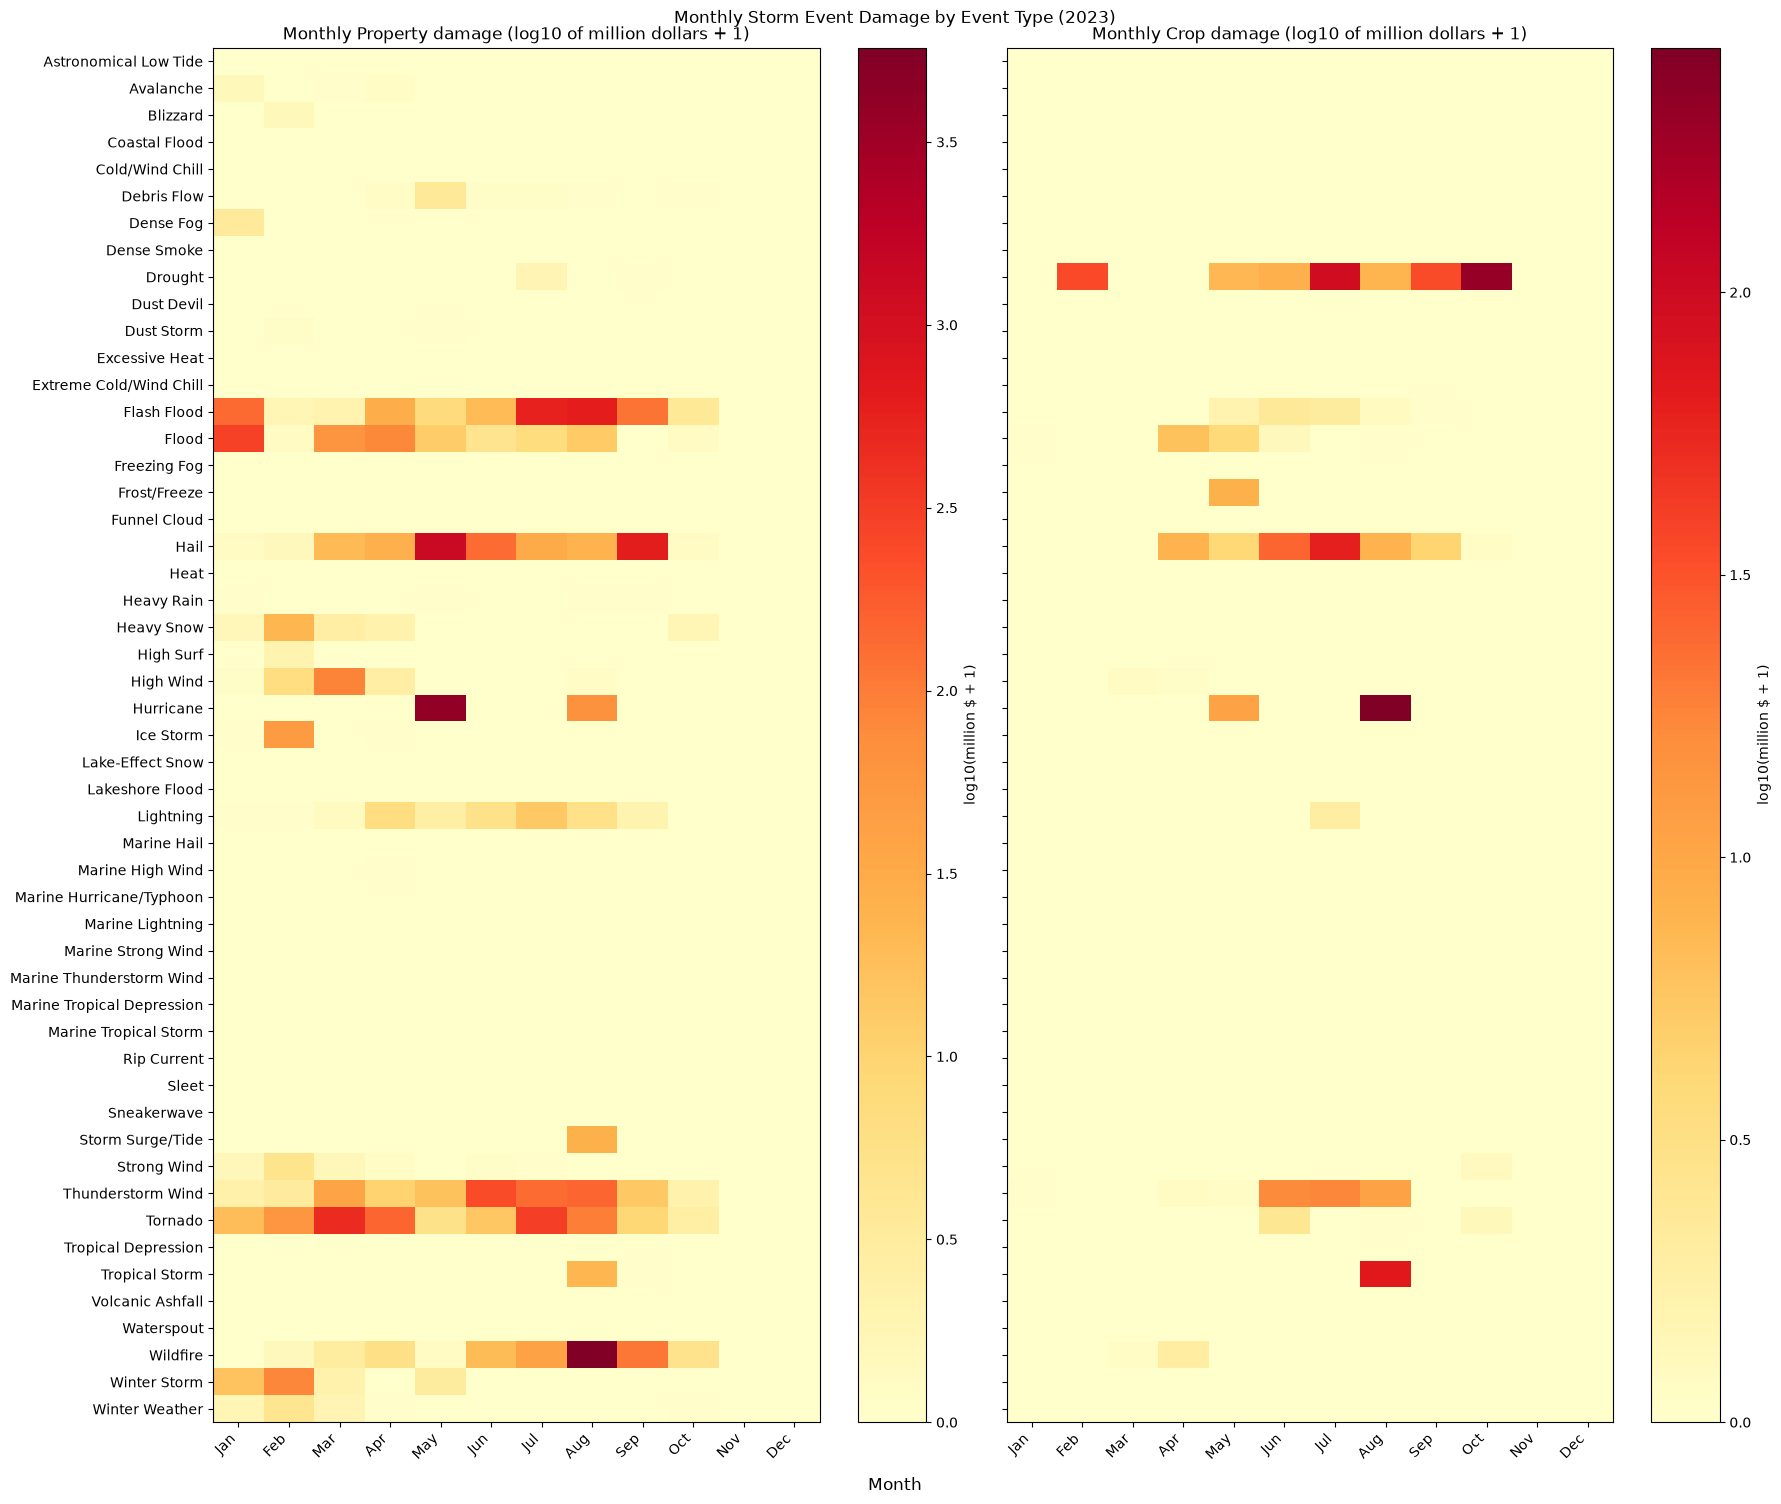

In [13]:
# Monthly property and crop damage by event type in 2023
seasonality = pd.read_sql_query(
    """
    SELECT
        CAST(strftime('%m', BEGIN_DATE_TIME) AS INTEGER) AS month,
        EVENT_TYPE AS event_type,
        SUM(COALESCE(DAMAGE_PROPERTY, 0)) AS property_damage,
        SUM(COALESCE(DAMAGE_CROPS, 0)) AS crop_damage
    FROM StormEvents
    WHERE date(BEGIN_DATE_TIME) >= '2023-01-01'
      AND date(BEGIN_DATE_TIME) <  '2024-01-01'
    GROUP BY month, event_type
    """,
    connection,
)
seasonality = seasonality.dropna(subset=["month", "event_type"])
seasonality["month"] = seasonality["month"].astype(int)

if seasonality.empty:
    print("No 2023 event records found.")
else:
    property_pivot = (
        seasonality.pivot(index="event_type", columns="month", values="property_damage")
        .reindex(columns=range(1, 13))
        .fillna(0)
    )
    crop_pivot = (
        seasonality.pivot(index="event_type", columns="month", values="crop_damage")
        .reindex(index=property_pivot.index, columns=range(1, 13))
        .fillna(0)
    )

    fig, axes = plt.subplots(
        1, 2, figsize=(18, max(8, len(property_pivot) * 0.3)), sharey=True
    )
    for ax, pivot, title in (
        (axes[0], property_pivot, "Property damage"),
        (axes[1], crop_pivot, "Crop damage"),
    ):
        values = np.log10(pivot.to_numpy() / 1_000_000 + 1)
        image = ax.imshow(values, aspect="auto", cmap="YlOrRd")
        ax.set_title(f"Monthly {title} (log10 of million dollars + 1)")
        ax.set_xticks(range(12))
        ax.set_xticklabels(
            ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
            rotation=45,
            ha="right",
        )
        ax.set_yticks(range(len(pivot.index)))
        ax.set_yticklabels(pivot.index)
        fig.colorbar(image, ax=ax, label="log10(million $ + 1)")
    fig.suptitle("Monthly Storm Event Damage by Event Type (2023)")
    fig.supxlabel("Month")
    fig.tight_layout()
    plt.show()


Event types most likely to report property damage (minimum 30 records):


,event_type,events,property_damage_events,property_probability_pct,ci_95_pct
0,Lightning,258,207,80.200000,"[74.9%, 84.6%]"
1,Strong Wind,965,668,69.200000,"[66.2%, 72.1%]"
2,Debris Flow,145,78,53.800000,"[45.7%, 61.7%]"
3,Thunderstorm Wind,20813,8614,41.400000,"[40.7%, 42.1%]"
4,Wildfire,281,116,41.300000,"[35.7%, 47.1%]"
5,Tornado,1414,484,34.200000,"[31.8%, 36.7%]"
6,Tropical Storm,226,59,26.100000,"[20.8%, 32.2%]"
7,Flash Flood,3394,862,25.400000,"[24.0%, 26.9%]"
8,Flood,2488,473,19.000000,"[17.5%, 20.6%]"
9,Avalanche,52,8,15.400000,"[8.0%, 27.5%]"



Event types most likely to report crop damage (minimum 30 records):


,event_type,events,crop_damage_events,crop_probability_pct,ci_95_pct
0,Frost/Freeze,483,16,3.300000,"[2.0%, 5.3%]"
1,Thunderstorm Wind,20813,582,2.800000,"[2.6%, 3.0%]"
2,Drought,4476,122,2.700000,"[2.3%, 3.2%]"
3,Lightning,258,6,2.300000,"[1.1%, 5.0%]"
4,Flood,2488,53,2.100000,"[1.6%, 2.8%]"
5,Tropical Storm,226,4,1.800000,"[0.7%, 4.5%]"
6,High Wind,3054,51,1.700000,"[1.3%, 2.2%]"
7,Tornado,1414,21,1.500000,"[1.0%, 2.3%]"
8,Wildfire,281,4,1.400000,"[0.6%, 3.6%]"
9,Debris Flow,145,2,1.400000,"[0.4%, 4.9%]"


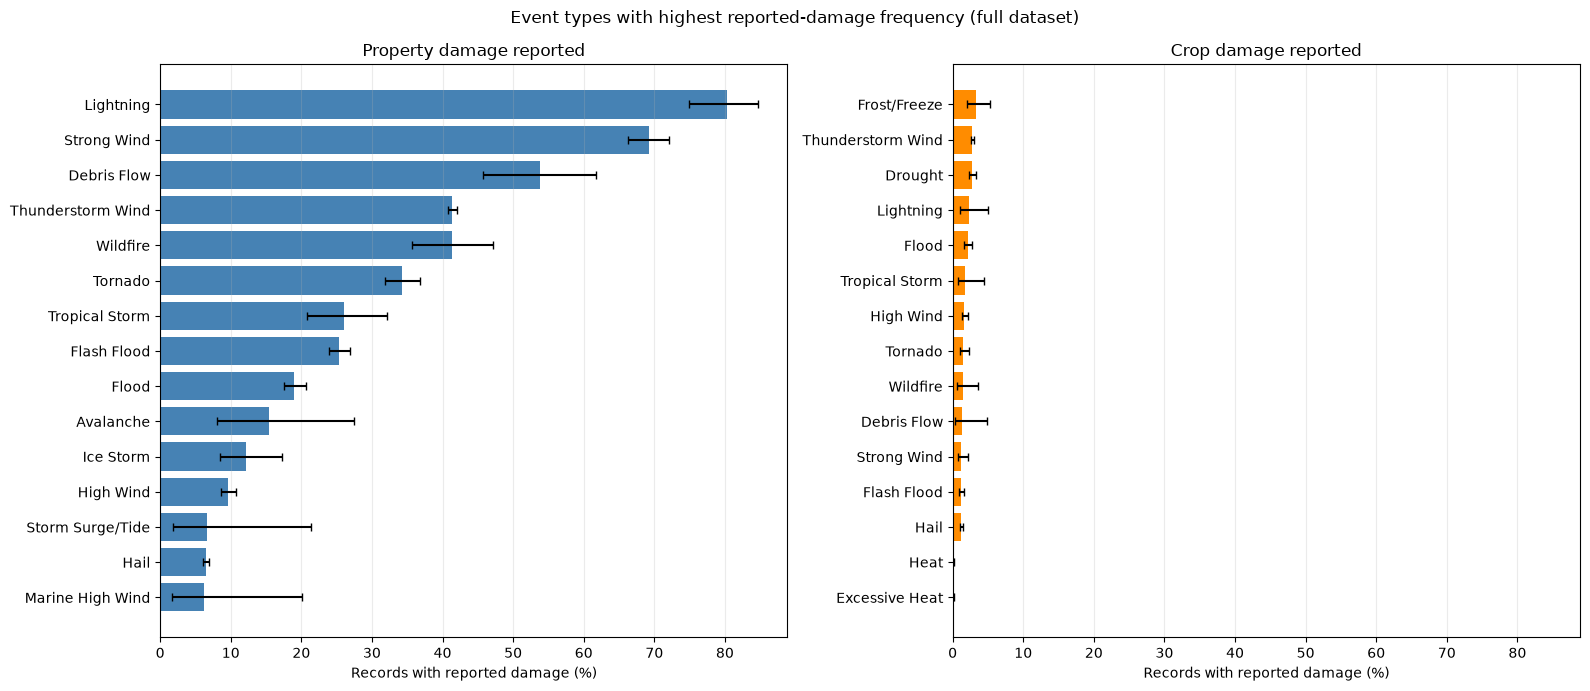

In [14]:
# Empirical chance that a storm-event record reports property or crop damage.
all_events = pd.read_sql_query(
    """
    SELECT
        EVENT_TYPE AS event_type,
        COALESCE(DAMAGE_PROPERTY, 0) AS property_damage,
        COALESCE(DAMAGE_CROPS, 0) AS crop_damage
    FROM StormEvents
    WHERE EVENT_TYPE IS NOT NULL
    """,
    connection,
)
all_events["has_property_damage"] = all_events["property_damage"] > 0
all_events["has_crop_damage"] = all_events["crop_damage"] > 0

damage_probability = (
    all_events.groupby("event_type")
    .agg(
        events=("event_type", "size"),
        property_damage_events=("has_property_damage", "sum"),
        crop_damage_events=("has_crop_damage", "sum"),
    )
    .query("events >= 30")
)
damage_probability["property_probability"] = (
    damage_probability["property_damage_events"] / damage_probability["events"]
)
damage_probability["crop_probability"] = (
    damage_probability["crop_damage_events"] / damage_probability["events"]
)

def wilson_interval(successes, trials, z=1.96):
    proportion = successes / trials
    denominator = 1 + z**2 / trials
    center = (proportion + z**2 / (2 * trials)) / denominator
    margin = z * np.sqrt(
        proportion * (1 - proportion) / trials + z**2 / (4 * trials**2)
    ) / denominator
    return center - margin, center + margin

(
    damage_probability["property_ci_lower"],
    damage_probability["property_ci_upper"],
) = wilson_interval(
    damage_probability["property_damage_events"], damage_probability["events"]
)
(
    damage_probability["crop_ci_lower"],
    damage_probability["crop_ci_upper"],
) = wilson_interval(
    damage_probability["crop_damage_events"], damage_probability["events"]
)

property_table = (
    damage_probability.sort_values("property_probability", ascending=False)
    .head(15)
    .reset_index()
    .assign(
        property_probability_pct=lambda d: (100 * d["property_probability"]).round(1),
        ci_95_pct=lambda d: [
            f"[{100 * low:.1f}%, {100 * high:.1f}%]"
            for low, high in zip(d["property_ci_lower"], d["property_ci_upper"])
        ],
    )[["event_type", "events", "property_damage_events", "property_probability_pct", "ci_95_pct"]]
)
print("Event types most likely to report property damage (minimum 30 records):")
display(format_damage_table(property_table))

crop_table = (
    damage_probability.sort_values("crop_probability", ascending=False)
    .head(15)
    .reset_index()
    .assign(
        crop_probability_pct=lambda d: (100 * d["crop_probability"]).round(1),
        ci_95_pct=lambda d: [
            f"[{100 * low:.1f}%, {100 * high:.1f}%]"
            for low, high in zip(d["crop_ci_lower"], d["crop_ci_upper"])
        ],
    )[["event_type", "events", "crop_damage_events", "crop_probability_pct", "ci_95_pct"]]
)
print()
print("Event types most likely to report crop damage (minimum 30 records):")
display(format_damage_table(crop_table))

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True)
for ax, probability_col, lower_col, upper_col, title, color in (
    (
        axes[0],
        "property_probability",
        "property_ci_lower",
        "property_ci_upper",
        "Property damage reported",
        "steelblue",
    ),
    (
        axes[1],
        "crop_probability",
        "crop_ci_lower",
        "crop_ci_upper",
        "Crop damage reported",
        "darkorange",
    ),
):
    chart = damage_probability.nlargest(15, probability_col).sort_values(probability_col)
    probability_pct = chart[probability_col] * 100
    ax.barh(chart.index.astype(str), probability_pct, color=color)
    ax.errorbar(
        probability_pct,
        chart.index.astype(str),
        xerr=[
            (chart[probability_col] - chart[lower_col]) * 100,
            (chart[upper_col] - chart[probability_col]) * 100,
        ],
        fmt="none",
        ecolor="black",
        capsize=3,
    )
    ax.set_yticks(range(len(chart)))
    ax.set_yticklabels(chart.index)
    ax.set_xlabel("Records with reported damage (%)")
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.25)

fig.suptitle("Event types with highest reported-damage frequency (full dataset)")
fig.tight_layout()
plt.show()
